In [35]:
import pandas as pd
from pathlib import Path
import matplotlib.pyplot as plt

PROJECT_PATH = Path.cwd().parent
RELATIV_PATH_PROCESSED_DATA = "data/processed/processed_dataset_2023.csv"
RELATIV_PATH_INTERIM_DATA = "data/interim/interim_dataset.csv"

In [36]:
df = pd.read_csv(PROJECT_PATH / RELATIV_PATH_PROCESSED_DATA)
df

,name,ref_area,time_period,population_ps,land_area_km2,gdp_per_capita_ppp_current_ppp,life_expectancy_yr,co2_emissions_per_capita_t,pm2_5_exposure_mcg_m3,urban_population_percentage_pt,health_expenditure_percentage_of_gdp_pt_gdp
0,Afghanistan,AFG,2023,41454761,652230.0,2201.722907,66.035,0.280995,37.948311,25.473053,14.985763
1,Angola,AGO,2023,36749906,1246700.0,9753.600468,64.617,0.743839,19.907569,69.851503,2.546929
2,Albania,ALB,2023,2411658,27400.0,24822.354309,79.602,1.750912,15.514103,58.210609,7.052403
3,United Arab Emirates,ARE,2023,10483751,71020.0,77955.295176,82.909,18.380482,57.186732,85.668070,4.970951
4,Argentina,ARG,2023,45538401,2736690.0,30221.497689,77.395,4.169905,14.346595,92.194513,10.269518
...,...,...,...,...,...,...,...,...,...,...,...
174,Vanuatu,VUT,2023,320409,12190.0,3567.818820,71.477,0.847979,6.993943,22.265197,4.118668
175,Samoa,WSM,2023,216663,2780.0,8194.807256,71.698,1.538334,4.579499,17.501280,6.781033
176,South Africa,ZAF,2023,63212384,1213090.0,15199.732982,66.139,6.759228,27.724711,63.582371,8.909668
177,Zambia,ZMB,2023,20723965,743390.0,4076.995087,66.349,0.548090,20.243049,45.028585,5.978411


## Helper functions

In [37]:
def describe_feature(df, col, bins=20, n_top=10, n_bottom=10):
    """Show summary stats, skew, max/min ratio, histogram and extreme countries for one feature."""
    s = df[col]
    display(s.describe().to_frame().T)
    print(f"skew      : {s.skew():.2f}")
    if s.min() > 0:
        print(f"max / min : {s.max() / s.min():.1f}")
    else:
        print(f"max / min : undefined (min = {s.min()})")
    s.hist(bins=bins)
    plt.title(col)
    plt.show()
    display(df.nlargest(n_top, col)[["name", "ref_area", col]])
    display(df.nsmallest(n_bottom, col)[["name", "ref_area", col]])


def show_skew_without(df, col, excluded_codes):
    """Print the skew of a feature after excluding countries by ISO3 code (ref_area)."""
    unknown = set(excluded_codes) - set(df["ref_area"])
    if unknown:
        raise ValueError(f"Unknown ref_area codes: {sorted(unknown)}")
    excluded = df["ref_area"].isin(excluded_codes)
    names = ", ".join(df.loc[excluded, "name"])
    print(f"skew without {names} : {df.loc[~excluded, col].skew():.2f}")

## Overview

In [38]:
overview = df.describe().T
overview["skew"] = df.skew(numeric_only=True)
overview

,count,mean,std,min,25%,50%,75%,max,skew
time_period,179.0,2.023000e+03,0.000000e+00,2023.000000,2.023000e+03,2.023000e+03,2.023000e+03,2.023000e+03,0.000000
population_ps,179.0,4.374603e+07,1.557160e+08,9816.000000,2.232406e+06,9.178298e+06,3.366895e+07,1.438070e+09,8.008406
land_area_km2,179.0,7.042531e+05,1.901206e+06,20.000000,2.545000e+04,1.289000e+05,5.249200e+05,1.637687e+07,5.326178
gdp_per_capita_ppp_current_ppp,179.0,2.818938e+04,2.892830e+04,1149.984058,6.908094e+03,1.774694e+04,4.274835e+04,1.505082e+05,1.703555
life_expectancy_yr,179.0,7.296118e+01,7.060216e+00,54.462000,6.733450e+01,7.349000e+01,7.812876e+01,8.415610e+01,-0.310080
co2_emissions_per_capita_t,179.0,4.591433e+00,8.002793e+00,0.000000,7.188935e-01,2.529670e+00,5.293895e+00,7.885711e+01,5.829636
pm2_5_exposure_mcg_m3,179.0,2.239294e+01,1.604327e+01,3.516653,1.109698e+01,1.791783e+01,3.039582e+01,1.077586e+02,1.754409
urban_population_percentage_pt,179.0,6.009427e+01,2.208562e+01,15.058102,4.231205e+01,6.175609e+01,7.831748e+01,1.000000e+02,-0.156355
health_expenditure_percentage_of_gdp_pt_gdp,179.0,6.772190e+00,3.335643e+00,1.326516,4.351277e+00,6.255747e+00,8.533167e+00,2.708968e+01,1.793512


## Feature-by-feature exploration

### Population

,count,mean,std,min,25%,50%,75%,max
population_ps,179.0,4.374603e+07,1.557160e+08,9816.0,2232405.5,9178298.0,33668945.5,1.438070e+09


skew      : 8.01
max / min : 146502.6


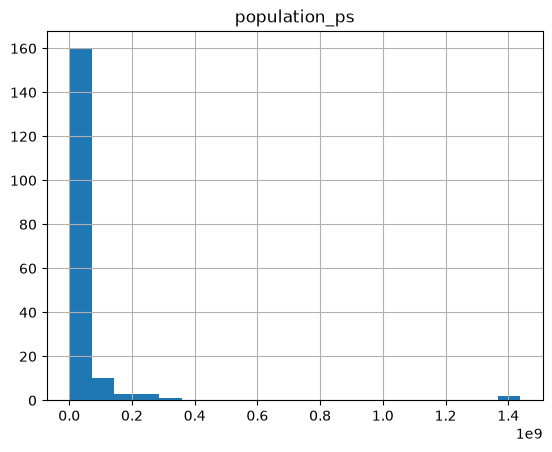

,name,ref_area,population_ps
74,India,IND,1438069596
31,China,CHN,1410710000
170,United States,USA,336755052
73,Indonesia,IDN,281190067
128,Pakistan,PAK,247504495


,name,ref_area,population_ps
166,Tuvalu,TUV,9816
125,Naoero,NRU,11875
132,Palau,PLW,17727
107,Marshall Islands,MHL,38827
89,St. Kitts and Nevis,KNA,46758
44,Dominica,DMA,66510
6,Antigua and Barbuda,ATG,93316
172,St. Vincent and the Grenadines,VCT,101323
162,Tonga,TON,104597
56,"Micronesia, Fed. Sts.",FSM,112630


In [39]:
describe_feature(df, "population_ps", n_top=5, n_bottom=20)

### land_area_km2

,count,mean,std,min,25%,50%,75%,max
land_area_km2,179.0,704253.096458,1.901206e+06,20.0,25450.0,128900.0,524920.0,16376870.0


skew      : 5.33
max / min : 818843.5


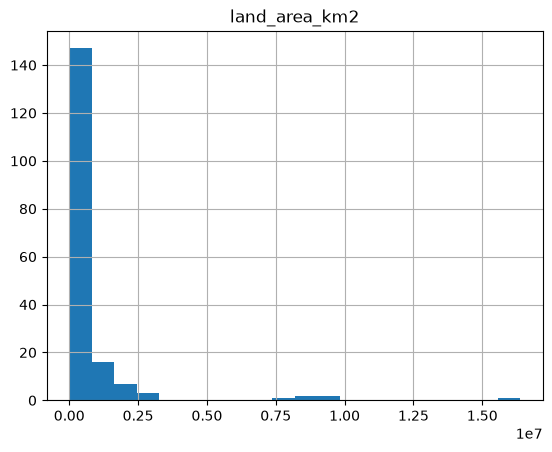

,name,ref_area,land_area_km2
139,Russian Federation,RUS,16376870.0
31,China,CHN,9388210.0
170,United States,USA,9147420.0
28,Canada,CAN,8788700.0
22,Brazil,BRA,8358140.0


,name,ref_area,land_area_km2
125,Naoero,NRU,20.0
166,Tuvalu,TUV,30.0
107,Marshall Islands,MHL,180.0
89,St. Kitts and Nevis,KNA,260.0
105,Maldives,MDV,298.0
110,Malta,MLT,320.0
66,Grenada,GRD,340.0
172,St. Vincent and the Grenadines,VCT,390.0
23,Barbados,BRB,430.0
6,Antigua and Barbuda,ATG,440.0


In [40]:
describe_feature(df, "land_area_km2", n_top=5, n_bottom=10)

### gdp_per_capita_ppp_current_ppp

,count,mean,std,min,25%,50%,75%,max
gdp_per_capita_ppp_current_ppp,179.0,28189.380374,28928.299069,1149.984058,6908.093621,17746.940554,42748.353148,150508.218887


skew      : 1.70
max / min : 130.9


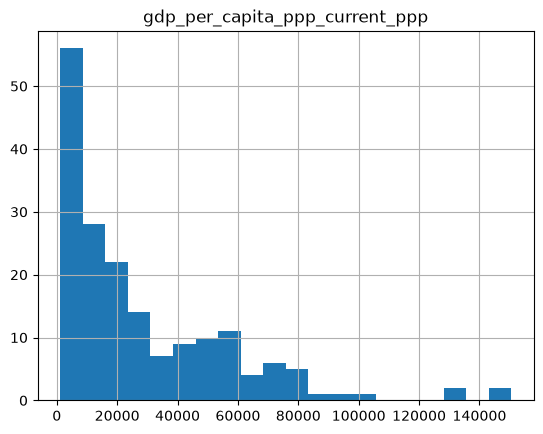

,name,ref_area,gdp_per_capita_ppp_current_ppp
100,Luxembourg,LUX,150508.218887
144,Singapore,SGP,143786.136293
75,Ireland,IRL,129682.607151
137,Qatar,QAT,129367.869671
123,Norway,NOR,103637.516844
29,Switzerland,CHE,95141.596094
24,Brunei Darussalam,BRN,85032.600874
170,United States,USA,82304.620427
122,Netherlands,NLD,81728.690463
78,Iceland,ISL,81608.447912


,name,ref_area,gdp_per_capita_ppp_current_ppp
10,Burundi,BDI,1149.984058
27,Central African Republic,CAF,1257.094357
148,"Somalia, Fed. Rep.",SOM,1555.610168
113,Mozambique,MOZ,1678.391182
34,"Congo, Dem. Rep.",COD,1730.622289
94,Liberia,LBR,1794.533409
104,Madagascar,MDG,1808.447790
116,Malawi,MWI,1830.464613
119,Niger,NER,1875.153068
0,Afghanistan,AFG,2201.722907


In [41]:
describe_feature(df, "gdp_per_capita_ppp_current_ppp")

### life_expectancy_yr

,count,mean,std,min,25%,50%,75%,max
life_expectancy_yr,179.0,72.961181,7.060216,54.462,67.3345,73.49,78.128756,84.156098


skew      : -0.31
max / min : 1.5


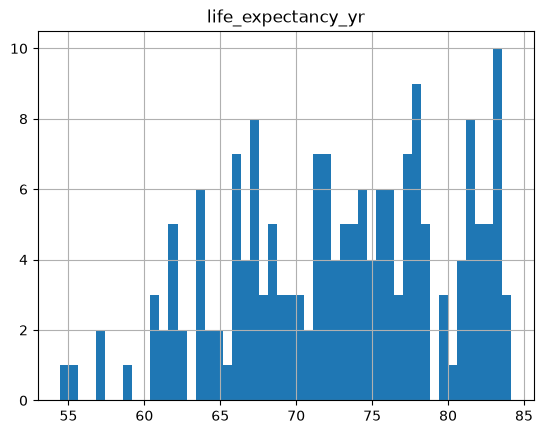

,name,ref_area,life_expectancy_yr
29,Switzerland,CHE,84.156098
83,Japan,JPN,84.041220
50,Spain,ESP,83.934146
90,"Korea, Rep.",KOR,83.429268
110,Malta,MLT,83.356098
80,Italy,ITA,83.351220
100,Luxembourg,LUX,83.309756
153,Sweden,SWE,83.309756
79,Israel,ISR,83.195122
91,Kuwait,KWT,83.187805


,name,ref_area,life_expectancy_yr
120,Nigeria,NGA,54.462
156,Chad,TCD,55.069
98,Lesotho,LSO,57.375
27,Central African Republic,CAF,57.408
148,"Somalia, Fed. Rep.",SOM,58.816
109,Mali,MLI,60.439
61,Guinea,GIN,60.740
12,Benin,BEN,60.774
13,Burkina Faso,BFA,61.092
119,Niger,NER,61.183


In [42]:
describe_feature(df, "life_expectancy_yr", bins=50)

### co2_emissions_per_capita_t

,count,mean,std,min,25%,50%,75%,max
co2_emissions_per_capita_t,179.0,4.591433,8.002793,0.0,0.718894,2.52967,5.293895,78.857111


skew      : 5.83
max / min : undefined (min = 0.0)


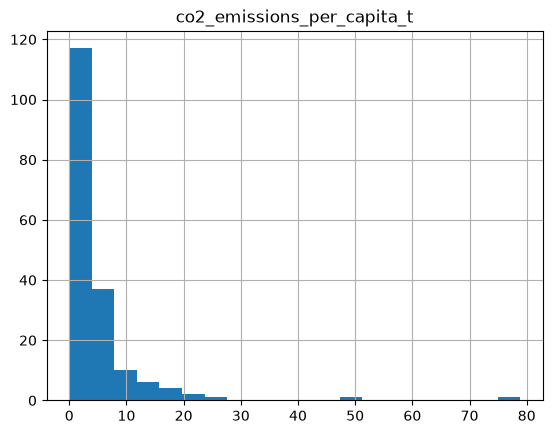

,name,ref_area,co2_emissions_per_capita_t
132,Palau,PLW,78.857111
137,Qatar,QAT,48.642637
16,Bahrain,BHR,24.532373
91,Kuwait,KWT,22.697211
24,Brunei Darussalam,BRN,21.143090
163,Trinidad and Tobago,TTO,19.706986
127,Oman,OMN,18.960091
141,Saudi Arabia,SAU,18.854074
3,United Arab Emirates,ARE,18.380482
28,Canada,CAN,14.160045


,name,ref_area,co2_emissions_per_capita_t
125,Naoero,NRU,0.000000
166,Tuvalu,TUV,0.000000
56,"Micronesia, Fed. Sts.",FSM,0.001776
107,Marshall Islands,MHL,0.002576
148,"Somalia, Fed. Rep.",SOM,0.046278
34,"Congo, Dem. Rep.",COD,0.058043
27,Central African Republic,CAF,0.064533
10,Burundi,BDI,0.069360
119,Niger,NER,0.120907
104,Madagascar,MDG,0.147269


In [43]:
describe_feature(df, "co2_emissions_per_capita_t")

<span style="color:red">Palau is 1.6 times higher than Qatar; this value looks suspicious and needs checking.</span>

In [44]:
show_skew_without(df, "co2_emissions_per_capita_t", ["PLW"])
show_skew_without(df, "co2_emissions_per_capita_t", ["PLW", "QAT"])

skew without Palau : 3.71
skew without Palau, Qatar : 2.16


<span style="color:red">Very small values, some of them zero.</span>

Checking past years for Naoero (Nauru), Tuvalu and Palau.

In [45]:
df[df["name"].isin(["Naoero", "Tuvalu", "Palau"])]

,name,ref_area,time_period,population_ps,land_area_km2,gdp_per_capita_ppp_current_ppp,life_expectancy_yr,co2_emissions_per_capita_t,pm2_5_exposure_mcg_m3,urban_population_percentage_pt,health_expenditure_percentage_of_gdp_pt_gdp
125,Naoero,NRU,2023,11875,20.0,13731.570475,62.109,0.000000,4.838579,100.000000,18.210760
132,Palau,PLW,2023,17727,460.0,18230.269863,69.269,78.857111,4.941100,79.153199,10.854682
166,Tuvalu,TUV,2023,9816,30.0,6151.010470,67.105,0.000000,5.224048,64.011721,27.089685


In [46]:
df_interim = pd.read_csv(PROJECT_PATH / RELATIV_PATH_INTERIM_DATA)
#df_interim[df_interim["ref_area"].isin(["NRU","TUV"])]
df_interim[df_interim["ref_area"].isin(["PLW"])]


,ref_area,time_period,population_ps,land_area_km2,gdp_per_capita_ppp_current_ppp,gdp_per_capita_usd_current_usd,life_expectancy_yr,co2_emissions_per_capita_t,pm2_5_exposure_mcg_m3,urban_population_percentage_pt,health_expenditure_percentage_of_gdp_pt_gdp
3850,PLW,2000,19178,460.0,10196.905422,7798.075106,64.499,110.647617,6.071854,69.587620,8.637289
3851,PLW,2001,19352,460.0,11091.793632,8239.263868,64.800,122.137247,6.838581,70.533711,7.796595
3852,PLW,2002,19503,460.0,11703.938499,8340.189650,65.076,74.045019,8.429599,72.381703,7.286911
3853,PLW,2003,19659,460.0,11588.369621,7862.392861,65.446,87.395086,6.874903,74.544485,8.095788
3854,PLW,2004,19820,460.0,12213.197855,8393.730291,65.816,76.781029,6.933207,76.445324,9.134798
3855,PLW,2005,19819,460.0,12960.167815,9367.686153,66.219,87.552349,5.939564,77.574268,8.631742
3856,PLW,2006,19593,460.0,13544.765128,9737.019439,66.633,86.653397,6.308509,78.306896,8.739992
3857,PLW,2007,19302,460.0,14308.232812,10155.047081,67.113,71.686872,6.241040,79.019601,8.837099
3858,PLW,2008,19009,460.0,14039.405618,10471.151001,67.562,73.533589,6.455550,79.663921,8.413782
3859,PLW,2009,18709,460.0,13414.354490,9837.498831,67.990,116.190069,7.647303,80.218671,9.630574


CO₂ emissions per capita are always zero for Naoero (Nauru) and Tuvalu.

Palau's CO₂ emissions are extreme every year, not just in 2023 (between 64 and 203 t per capita over 2000–2024). The cause is not established, and the value is not representative of a development profile.

### pm2_5_exposure_mcg_m3

,count,mean,std,min,25%,50%,75%,max
pm2_5_exposure_mcg_m3,179.0,22.392944,16.043274,3.516653,11.096981,17.917829,30.39582,107.758572


skew      : 1.75
max / min : 30.6


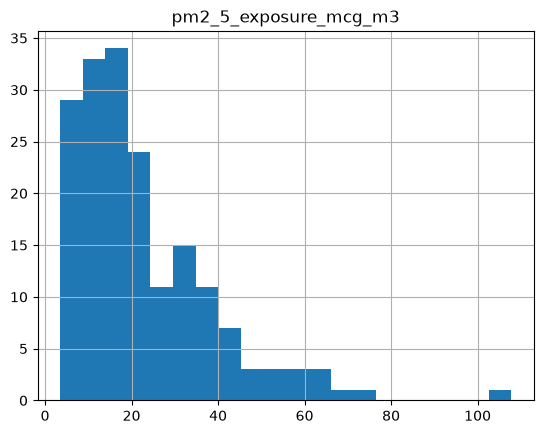

,name,ref_area,pm2_5_exposure_mcg_m3
137,Qatar,QAT,107.758572
141,Saudi Arabia,SAU,73.517975
14,Bangladesh,BGD,69.252552
120,Nigeria,NGA,65.740619
119,Niger,NER,65.230289
91,Kuwait,KWT,62.348436
128,Pakistan,PAK,58.374518
3,United Arab Emirates,ARE,57.186732
16,Bahrain,BHR,56.565485
33,Cameroon,CMR,55.603593


,name,ref_area,pm2_5_exposure_mcg_m3
56,"Micronesia, Fed. Sts.",FSM,3.516653
88,Kiribati,KIR,3.867047
107,Marshall Islands,MHL,4.101597
53,Finland,FIN,4.566639
175,Samoa,WSM,4.579499
162,Tonga,TON,4.689162
125,Naoero,NRU,4.838579
78,Iceland,ISL,4.932964
132,Palau,PLW,4.941100
166,Tuvalu,TUV,5.224048


In [47]:
describe_feature(df, "pm2_5_exposure_mcg_m3")

In [48]:
show_skew_without(df, "pm2_5_exposure_mcg_m3", ["QAT"])

skew without Qatar : 1.26


### urban_population_percentage_pt

,count,mean,std,min,25%,50%,75%,max
urban_population_percentage_pt,179.0,60.09427,22.085615,15.058102,42.312052,61.756092,78.317482,100.0


skew      : -0.16
max / min : 6.6


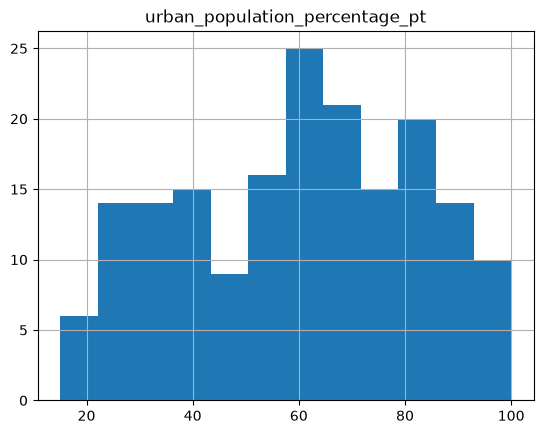

,name,ref_area,urban_population_percentage_pt
16,Bahrain,BHR,100.000000
91,Kuwait,KWT,100.000000
125,Naoero,NRU,100.000000
144,Singapore,SGP,100.000000
137,Qatar,QAT,99.283533
110,Malta,MLT,95.627228
169,Uruguay,URY,95.543961
122,Netherlands,NLD,95.322168
100,Luxembourg,LUX,94.801530
78,Iceland,ISL,94.151826


,name,ref_area,urban_population_percentage_pt
133,Papua New Guinea,PNG,15.058102
116,Malawi,MWI,16.974875
175,Samoa,WSM,17.501280
119,Niger,NER,17.750687
97,Sri Lanka,LKA,20.145535
162,Tonga,TON,21.147945
174,Vanuatu,VUT,22.265197
56,"Micronesia, Fed. Sts.",FSM,22.433401
52,Ethiopia,ETH,23.058647
10,Burundi,BDI,23.553477


In [49]:
describe_feature(df, "urban_population_percentage_pt", bins=12)

### health_expenditure_percentage_of_gdp_pt_gdp

,count,mean,std,min,25%,50%,75%,max
health_expenditure_percentage_of_gdp_pt_gdp,179.0,6.77219,3.335643,1.326516,4.351277,6.255747,8.533167,27.089685


skew      : 1.79
max / min : 20.4


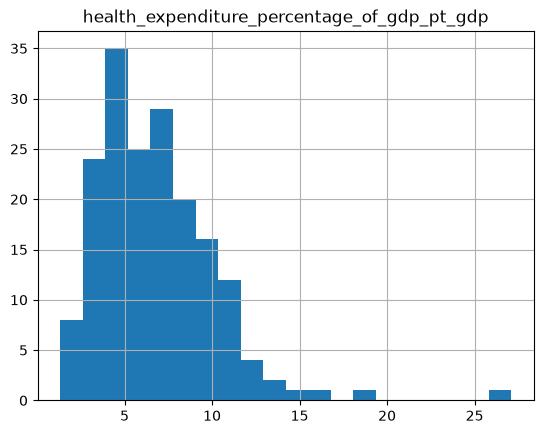

,name,ref_area,health_expenditure_percentage_of_gdp_pt_gdp
166,Tuvalu,TUV,27.089685
125,Naoero,NRU,18.210760
170,United States,USA,16.694149
0,Afghanistan,AFG,14.985763
107,Marshall Islands,MHL,13.405290
94,Liberia,LBR,13.005749
56,"Micronesia, Fed. Sts.",FSM,12.880876
98,Lesotho,LSO,12.611821
42,Germany,DEU,11.744287
29,Switzerland,CHE,11.690961


,name,ref_area,health_expenditure_percentage_of_gdp_pt_gdp
92,Lao PDR,LAO,1.326516
14,Bangladesh,BGD,2.170146
24,Brunei Darussalam,BRN,2.228607
43,Djibouti,DJI,2.283160
68,Guyana,GUY,2.466738
128,Pakistan,PAK,2.519883
137,Qatar,QAT,2.523588
1,Angola,AGO,2.546929
73,Indonesia,IDN,2.702399
52,Ethiopia,ETH,2.803103


In [50]:
describe_feature(df, "health_expenditure_percentage_of_gdp_pt_gdp")

In [51]:
show_skew_without(df, "health_expenditure_percentage_of_gdp_pt_gdp", ["TUV"])

skew without Tuvalu : 0.84


#### Health expenditure (% of GDP): an ambiguous feature

It is a ratio of health spending to total GDP: its value depends as much on GDP as on spending. As a result, the top of the ranking mixes very different situations.

**At the top**
- Rich countries (United States, Germany, Switzerland): costly health systems absorb a large share of wealth.
- Poor countries (Afghanistan, Liberia, Lesotho): very low GDP, so any spending or foreign aid pushes the ratio up (hypothesis to check).
- Micro-states (Tuvalu, Nauru, Marshall Islands, Micronesia): same mechanism, small GDP and possible external funding (hypothesis to check).

**At the bottom**
- Many poor countries (Laos, Bangladesh, Djibouti, Angola): small GDP too, but very low spending, probably little foreign aid.
- Qatar, Brunei: GDP inflated by hydrocarbons, hence a low ratio despite probably high per-capita spending.

**Problem**: poor countries end up at both extremes (Afghanistan and Liberia at the top, Laos and Bangladesh at the bottom), and the same figure can mean "developed health system" or "aid-dependent economy". A clustering risks mixing them up.

**Lead**: compute health spending per capita (% / 100 × GDP per capita PPP) to see whether it removes the ambiguity. Test on Afghanistan, Liberia, Germany, Qatar, then check redundancy with GDP per capita in the correlation analysis (notebook 05).

### health_exp_per_capita

In [52]:
df["health_exp_per_capita"] = df["health_expenditure_percentage_of_gdp_pt_gdp"] / 100 * df["gdp_per_capita_ppp_current_ppp"]

,count,mean,std,min,25%,50%,75%,max
health_exp_per_capita,179.0,2085.95835,2524.183684,58.24416,331.102737,1090.172675,3021.013077,13740.055968


skew      : 1.85
max / min : 235.9


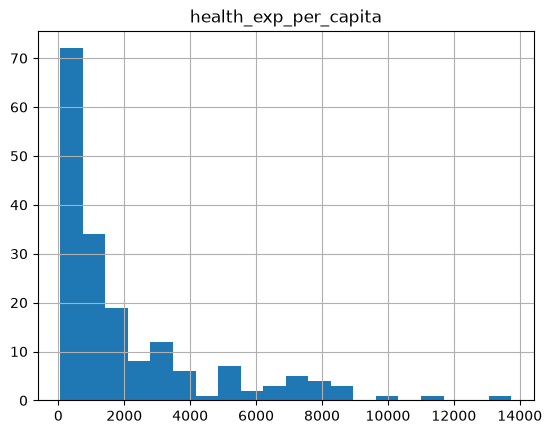

,name,ref_area,health_exp_per_capita
170,United States,USA,13740.055968
29,Switzerland,CHE,11122.966894
123,Norway,NOR,9772.245739
100,Luxembourg,LUX,8711.084591
75,Ireland,IRL,8527.130698
42,Germany,DEU,8418.778356
8,Austria,AUT,8202.415707
122,Netherlands,NLD,8035.156203
11,Belgium,BEL,7772.857148
153,Sweden,SWE,7720.753439


,name,ref_area,health_exp_per_capita
148,"Somalia, Fed. Rep.",SOM,58.244160
104,Madagascar,MDG,61.997750
34,"Congo, Dem. Rep.",COD,63.772583
142,Sudan,SDN,69.028862
119,Niger,NER,75.924160
52,Ethiopia,ETH,85.800321
62,"Gambia, The",GMB,95.138200
10,Burundi,BDI,104.587738
71,Haiti,HTI,105.057964
116,Malawi,MWI,119.613467


In [53]:
describe_feature(df, "health_exp_per_capita")

In [54]:
show_skew_without(df, "health_exp_per_capita", ["USA"])
show_skew_without(df, "health_exp_per_capita", ["USA", "CHE"])

skew without United States : 1.65
skew without Switzerland, United States : 1.58


This feature is far more meaningful than the previous one, which ultimately did not tell us much.

It is also much less ambiguous. However, it raises a real problem: **it appears to be strongly positively correlated with GDP per capita.** This is expected, since it is built from GDP per capita (health spending per capita = share of GDP × GDP per capita).

The correlation has not been measured yet (Spearman, plus a log-log scatter plot), and it must be resolved before the clustering: otherwise "development" would count almost twice in the distances.

# Decision: exclude countries with fewer than 300,000 inhabitants in 2023.

**Methodological rationale:** for these countries, ratios (CO₂ per capita, health spending as % of GDP) are dominated by a single facility, foreign aid or an estimated value. Evidence: Nauru and Tuvalu (CO₂ at zero since 2000), Palau (CO₂ between 64 and 203 t every year), and Tuvalu and Nauru (top of health spending as % of GDP).

**Cost:** the atlas now describes countries with at least 300,000 inhabitants. It is no longer "all complete countries".

In [55]:
MIN_POPULATION = 300000
df_without_micro_countries = df[df["population_ps"]>=MIN_POPULATION]

### Overview

In [56]:
overview = df_without_micro_countries.describe().T
overview["skew"] = df_without_micro_countries.skew(numeric_only=True)
overview

,count,mean,std,min,25%,50%,75%,max,skew
time_period,162.0,2.023000e+03,0.000000e+00,2023.000000,2.023000e+03,2.023000e+03,2.023000e+03,2.023000e+03,0.000000
population_ps,162.0,4.832505e+07,1.630510e+08,320409.000000,3.411347e+06,1.055740e+07,3.552080e+07,1.438070e+09,7.637927
land_area_km2,162.0,7.780924e+05,1.984562e+06,298.000000,3.963222e+04,1.921650e+05,6.126850e+05,1.637687e+07,5.075149
gdp_per_capita_ppp_current_ppp,162.0,2.940924e+04,2.998047e+04,1149.984058,6.879186e+03,1.765572e+04,4.643969e+04,1.505082e+05,1.589310
life_expectancy_yr,162.0,7.317924e+01,7.276984e+00,54.462000,6.736100e+01,7.401389e+01,7.866729e+01,8.415610e+01,-0.370231
co2_emissions_per_capita_t,162.0,4.427112e+00,5.944908e+00,0.046278,7.599045e-01,2.711269e+00,5.738561e+00,4.864264e+01,3.586127
pm2_5_exposure_mcg_m3,162.0,2.392857e+01,1.607347e+01,4.566639,1.341523e+01,1.963924e+01,3.130308e+01,1.077586e+02,1.733335
urban_population_percentage_pt,162.0,6.109308e+01,2.163931e+01,15.058102,4.306331e+01,6.246279e+01,7.877898e+01,1.000000e+02,-0.183583
health_expenditure_percentage_of_gdp_pt_gdp,162.0,6.546648e+00,2.817767e+00,1.326516,4.287220e+00,6.279178e+00,8.421479e+00,1.669415e+01,0.594454
health_exp_per_capita,162.0,2.184700e+03,2.627519e+03,58.244160,2.677526e+02,1.091720e+03,3.116068e+03,1.374006e+04,1.714955


### Rechecking active features

,count,mean,std,min,25%,50%,75%,max
gdp_per_capita_ppp_current_ppp,162.0,29409.24117,29980.469922,1149.984058,6879.185664,17655.715895,46439.6899,150508.218887


skew      : 1.59
max / min : 130.9


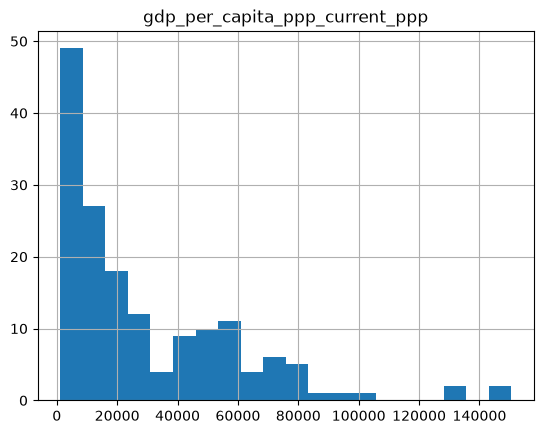

,name,ref_area,gdp_per_capita_ppp_current_ppp
100,Luxembourg,LUX,150508.218887
144,Singapore,SGP,143786.136293
75,Ireland,IRL,129682.607151
137,Qatar,QAT,129367.869671
123,Norway,NOR,103637.516844
29,Switzerland,CHE,95141.596094
24,Brunei Darussalam,BRN,85032.600874
170,United States,USA,82304.620427
122,Netherlands,NLD,81728.690463
78,Iceland,ISL,81608.447912


,name,ref_area,gdp_per_capita_ppp_current_ppp
10,Burundi,BDI,1149.984058
27,Central African Republic,CAF,1257.094357
148,"Somalia, Fed. Rep.",SOM,1555.610168
113,Mozambique,MOZ,1678.391182
34,"Congo, Dem. Rep.",COD,1730.622289


In [57]:
describe_feature(df_without_micro_countries, "gdp_per_capita_ppp_current_ppp", n_bottom=5)

,count,mean,std,min,25%,50%,75%,max
gdp_per_capita_ppp_current_ppp,162.0,29409.24117,29980.469922,1149.984058,6879.185664,17655.715895,46439.6899,150508.218887


skew      : 1.59
max / min : 130.9


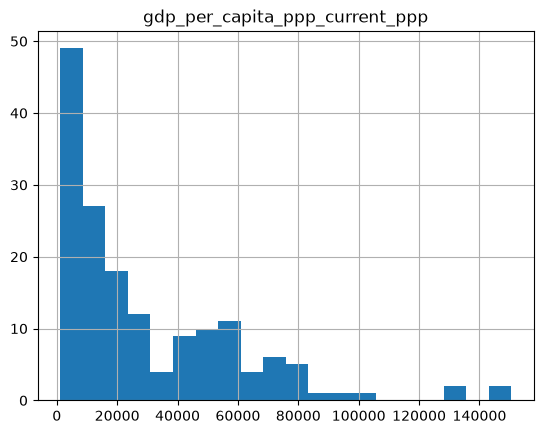

,name,ref_area,gdp_per_capita_ppp_current_ppp
100,Luxembourg,LUX,150508.218887
144,Singapore,SGP,143786.136293
75,Ireland,IRL,129682.607151
137,Qatar,QAT,129367.869671
123,Norway,NOR,103637.516844
29,Switzerland,CHE,95141.596094
24,Brunei Darussalam,BRN,85032.600874
170,United States,USA,82304.620427
122,Netherlands,NLD,81728.690463
78,Iceland,ISL,81608.447912


,name,ref_area,gdp_per_capita_ppp_current_ppp
10,Burundi,BDI,1149.984058
27,Central African Republic,CAF,1257.094357
148,"Somalia, Fed. Rep.",SOM,1555.610168
113,Mozambique,MOZ,1678.391182
34,"Congo, Dem. Rep.",COD,1730.622289
94,Liberia,LBR,1794.533409
104,Madagascar,MDG,1808.447790
116,Malawi,MWI,1830.464613
119,Niger,NER,1875.153068
0,Afghanistan,AFG,2201.722907


In [58]:
describe_feature(df_without_micro_countries, "gdp_per_capita_ppp_current_ppp")

In [59]:
show_skew_without(df_without_micro_countries, "gdp_per_capita_ppp_current_ppp", ["LUX", "SGP"])

skew without Luxembourg, Singapore : 1.30


,count,mean,std,min,25%,50%,75%,max
life_expectancy_yr,162.0,73.17924,7.276984,54.462,67.361,74.01389,78.667293,84.156098


skew      : -0.37
max / min : 1.5


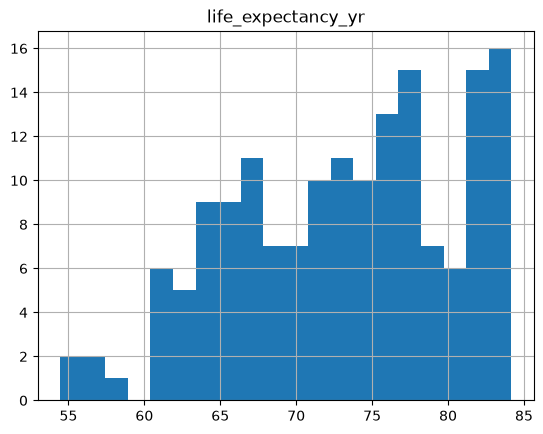

,name,ref_area,life_expectancy_yr
29,Switzerland,CHE,84.156098
83,Japan,JPN,84.041220
50,Spain,ESP,83.934146
90,"Korea, Rep.",KOR,83.429268
110,Malta,MLT,83.356098
80,Italy,ITA,83.351220
100,Luxembourg,LUX,83.309756
153,Sweden,SWE,83.309756
79,Israel,ISR,83.195122
91,Kuwait,KWT,83.187805


,name,ref_area,life_expectancy_yr
120,Nigeria,NGA,54.462
156,Chad,TCD,55.069
98,Lesotho,LSO,57.375
27,Central African Republic,CAF,57.408
148,"Somalia, Fed. Rep.",SOM,58.816
109,Mali,MLI,60.439
61,Guinea,GIN,60.740
12,Benin,BEN,60.774
13,Burkina Faso,BFA,61.092
119,Niger,NER,61.183


In [60]:
describe_feature(df_without_micro_countries, "life_expectancy_yr")

,count,mean,std,min,25%,50%,75%,max
co2_emissions_per_capita_t,162.0,4.427112,5.944908,0.046278,0.759904,2.711269,5.738561,48.642637


skew      : 3.59
max / min : 1051.1


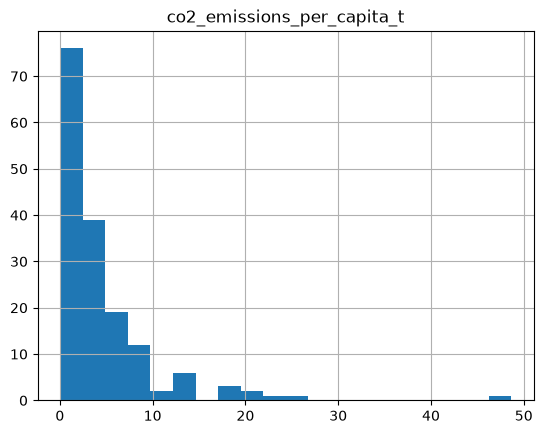

,name,ref_area,co2_emissions_per_capita_t
137,Qatar,QAT,48.642637
16,Bahrain,BHR,24.532373
91,Kuwait,KWT,22.697211
24,Brunei Darussalam,BRN,21.143090
163,Trinidad and Tobago,TTO,19.706986
127,Oman,OMN,18.960091
141,Saudi Arabia,SAU,18.854074
3,United Arab Emirates,ARE,18.380482
28,Canada,CAN,14.160045
7,Australia,AUS,14.159670


,name,ref_area,co2_emissions_per_capita_t
148,"Somalia, Fed. Rep.",SOM,0.046278
34,"Congo, Dem. Rep.",COD,0.058043
27,Central African Republic,CAF,0.064533
10,Burundi,BDI,0.069360
119,Niger,NER,0.120907
104,Madagascar,MDG,0.147269
52,Ethiopia,ETH,0.147768
156,Chad,TCD,0.150566
94,Liberia,LBR,0.152830
63,Guinea-Bissau,GNB,0.152925


In [61]:
describe_feature(df_without_micro_countries, "co2_emissions_per_capita_t")

In [62]:
show_skew_without(df_without_micro_countries, "co2_emissions_per_capita_t", ["QAT"])

skew without Qatar : 2.05


,count,mean,std,min,25%,50%,75%,max
pm2_5_exposure_mcg_m3,162.0,23.928567,16.073472,4.566639,13.415229,19.639242,31.303085,107.758572


skew      : 1.73
max / min : 23.6


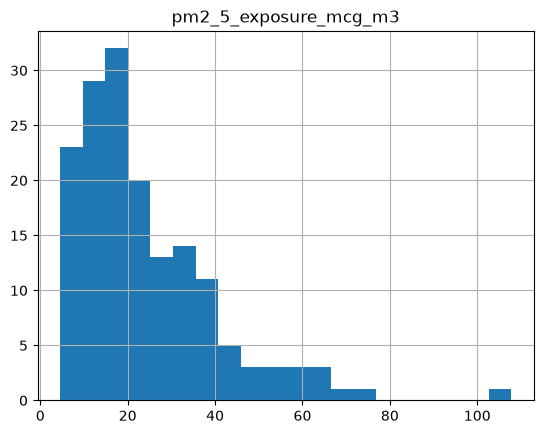

,name,ref_area,pm2_5_exposure_mcg_m3
137,Qatar,QAT,107.758572
141,Saudi Arabia,SAU,73.517975
14,Bangladesh,BGD,69.252552
120,Nigeria,NGA,65.740619
119,Niger,NER,65.230289
91,Kuwait,KWT,62.348436
128,Pakistan,PAK,58.374518
3,United Arab Emirates,ARE,57.186732
16,Bahrain,BHR,56.565485
33,Cameroon,CMR,55.603593


,name,ref_area,pm2_5_exposure_mcg_m3
53,Finland,FIN,4.566639
78,Iceland,ISL,4.932964
153,Sweden,SWE,5.259381
17,"Bahamas, The",BHS,5.281914
123,Norway,NOR,5.521411
51,Estonia,EST,5.918446
7,Australia,AUS,6.414739
54,Fiji,FJI,6.448721
28,Canada,CAN,6.550392
126,New Zealand,NZL,6.881385


In [63]:
describe_feature(df_without_micro_countries, "pm2_5_exposure_mcg_m3")

In [64]:
show_skew_without(df_without_micro_countries, "pm2_5_exposure_mcg_m3", ["QAT"])

skew without Qatar : 1.22


,count,mean,std,min,25%,50%,75%,max
urban_population_percentage_pt,162.0,61.093085,21.639309,15.058102,43.063308,62.462792,78.778982,100.0


skew      : -0.18
max / min : 6.6


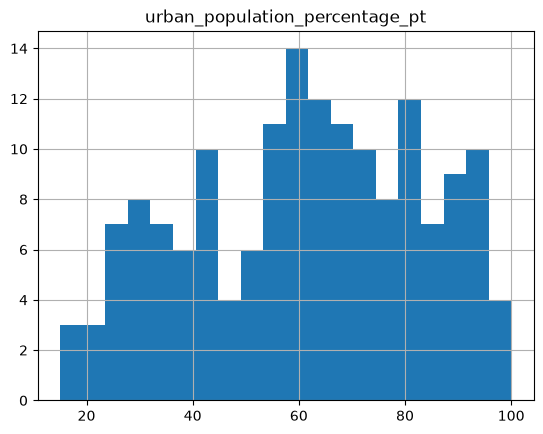

,name,ref_area,urban_population_percentage_pt
16,Bahrain,BHR,100.000000
91,Kuwait,KWT,100.000000
144,Singapore,SGP,100.000000
137,Qatar,QAT,99.283533
110,Malta,MLT,95.627228
169,Uruguay,URY,95.543961
122,Netherlands,NLD,95.322168
100,Luxembourg,LUX,94.801530
78,Iceland,ISL,94.151826
82,Jordan,JOR,92.682237


,name,ref_area,urban_population_percentage_pt
133,Papua New Guinea,PNG,15.058102
116,Malawi,MWI,16.974875
119,Niger,NER,17.750687
97,Sri Lanka,LKA,20.145535
174,Vanuatu,VUT,22.265197
52,Ethiopia,ETH,23.058647
10,Burundi,BDI,23.553477
0,Afghanistan,AFG,25.473053
154,Eswatini,SWZ,25.808188
159,Tajikistan,TJK,26.189013


In [65]:
describe_feature(df_without_micro_countries, "urban_population_percentage_pt")

,count,mean,std,min,25%,50%,75%,max
health_expenditure_percentage_of_gdp_pt_gdp,162.0,6.546648,2.817767,1.326516,4.28722,6.279178,8.421479,16.694149


skew      : 0.59
max / min : 12.6


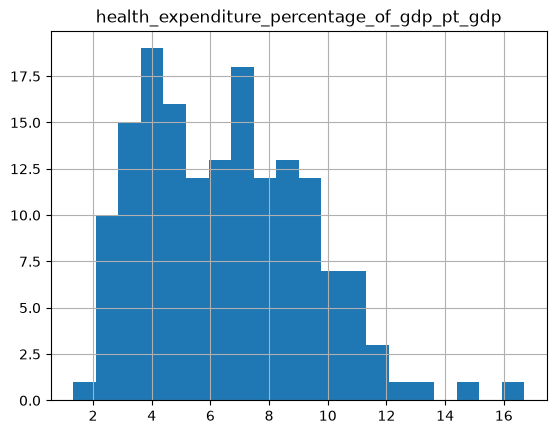

,name,ref_area,health_expenditure_percentage_of_gdp_pt_gdp
170,United States,USA,16.694149
0,Afghanistan,AFG,14.985763
94,Liberia,LBR,13.005749
98,Lesotho,LSO,12.611821
42,Germany,DEU,11.744287
29,Switzerland,CHE,11.690961
55,France,FRA,11.519746
28,Canada,CAN,11.186929
8,Austria,AUT,11.152973
153,Sweden,SWE,11.152915


,name,ref_area,health_expenditure_percentage_of_gdp_pt_gdp
92,Lao PDR,LAO,1.326516
14,Bangladesh,BGD,2.170146
24,Brunei Darussalam,BRN,2.228607
43,Djibouti,DJI,2.283160
68,Guyana,GUY,2.466738
128,Pakistan,PAK,2.519883
137,Qatar,QAT,2.523588
1,Angola,AGO,2.546929
73,Indonesia,IDN,2.702399
52,Ethiopia,ETH,2.803103


In [66]:
describe_feature(df_without_micro_countries, "health_expenditure_percentage_of_gdp_pt_gdp")

,count,mean,std,min,25%,50%,75%,max
health_exp_per_capita,162.0,2184.699712,2627.518854,58.24416,267.752569,1091.720372,3116.067515,13740.055968


skew      : 1.71
max / min : 235.9


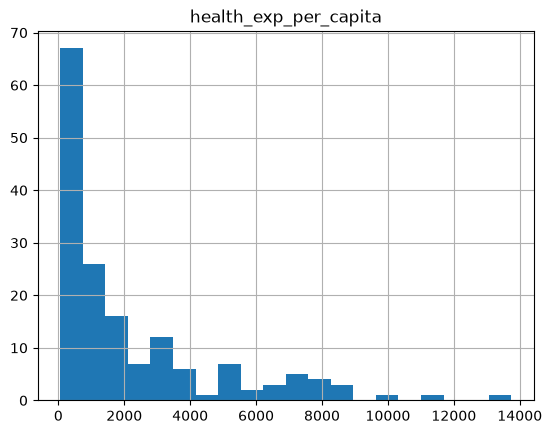

,name,ref_area,health_exp_per_capita
170,United States,USA,13740.055968
29,Switzerland,CHE,11122.966894
123,Norway,NOR,9772.245739
100,Luxembourg,LUX,8711.084591
75,Ireland,IRL,8527.130698
42,Germany,DEU,8418.778356
8,Austria,AUT,8202.415707
122,Netherlands,NLD,8035.156203
11,Belgium,BEL,7772.857148
153,Sweden,SWE,7720.753439


,name,ref_area,health_exp_per_capita
148,"Somalia, Fed. Rep.",SOM,58.244160
104,Madagascar,MDG,61.997750
34,"Congo, Dem. Rep.",COD,63.772583
142,Sudan,SDN,69.028862
119,Niger,NER,75.924160
52,Ethiopia,ETH,85.800321
62,"Gambia, The",GMB,95.138200
10,Burundi,BDI,104.587738
71,Haiti,HTI,105.057964
116,Malawi,MWI,119.613467


In [67]:
describe_feature(df_without_micro_countries, "health_exp_per_capita")

In [68]:
show_skew_without(df_without_micro_countries, "health_exp_per_capita", ["USA"])
show_skew_without(df_without_micro_countries, "health_exp_per_capita", ["USA", "CHE"])
show_skew_without(df_without_micro_countries, "health_exp_per_capita", ["USA", "CHE", "NOR"])

skew without United States : 1.52
skew without Switzerland, United States : 1.45
skew without Switzerland, Norway, United States : 1.42


### Summary: effect of excluding micro-states (179 → 162 countries)

| Feature | Skew before → after | Max/min before → after |
|---|---|---|
| GDP per capita | 1.70 → 1.59 | 131 → 131 |
| Life expectancy | −0.31 → −0.37 | 1.5 → 1.5 |
| CO₂ per capita | 5.83 → **3.59** | ∞ (zeros) → **1,051** |
| PM2.5 | 1.75 → 1.73 | 31 → 24 |
| Urbanisation | −0.16 → −0.18 | 6.6 → 6.6 |
| Health (% of GDP) | 1.79 → **0.59** | 20 → 13 |
| Health per capita | 1.83 → 1.71 | 236 → 236 |

**Reading:** the interpretation of the features does not change. The exclusion only removed the problems specific to micro-states:

- **CO₂**: no more zeros (Nauru, Tuvalu) and no more outlier (Palau). A log transform is now possible; log vs raw remains a business decision. Qatar stays far above the rest (48.6 t, twice Bahrain).
- **Health (% of GDP)**: the drop in skew comes from removing Tuvalu and Nauru. The ambiguity remains (Afghanistan, Liberia, Lesotho still at the top, next to the United States and Germany).
- **Other features**: almost unchanged, micro-states were not their extreme values.